# Figure S10 · Discovery Glasser360 (alternative atlas)

In [1]:
from pathlib import Path
import sys
base_path = next(
    p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
    if (p / "CODE").is_dir() and (p / "DATA").is_dir()
)
sys.path.insert(0, str(Path(base_path) / 'CODE'))
from utils.network_plots import plot_network_task_radarplot_from_values
from utils.statistics import mean_parcelwise


In [2]:
import matplotlib.pyplot as plt
from utils.surface import plot_parcelwise_with_roi_surface_direct
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
import os
import re

In [3]:
output_path = f'{base_path}/FIGURES/supplementary/Fig_S9'
os.makedirs(output_path, exist_ok=True)

## S10A: Mean Hurst Maps

In [5]:
data_path = f"{base_path}/RESULTS/discovery_dataset/hurst_Glasser360/dataframes/df_hurst_parcelwise_FIN_D4_modwt_1_5_padding_0_decimate_0_residuals_w_rest_IQR_cleaned.csv"
field = "Hursts"
max_color = "#003674"

In [6]:
data_df = pd.read_csv(data_path)
os.makedirs(output_path, exist_ok=True)

mean_map = mean_parcelwise(data_df, field=field)
print( "Mean Hurst:", np.mean(mean_map), "Std Hurst:", np.std(mean_map), "Min Hurst:", np.min(mean_map), "Max Hurst:", np.max(mean_map))

Mean Hurst: 1.1972936006328434 Std Hurst: 0.16310568551407184 Min Hurst: 0.8486183066426118 Max Hurst: 1.6097356842027177


In [7]:
data_df = pd.read_csv(data_path)
os.makedirs(output_path, exist_ok=True)

mapname = f'{output_path}/mean_hurst.png'
mean_map = mean_parcelwise(data_df, field=field)
plot_parcelwise_with_roi_surface_direct(
        matrix=mean_map,
        lh_annot_path=f"{base_path}/DATA/templates/lh.HCP-MMP1.annot", 
        rh_annot_path=f"{base_path}/DATA/templates/rh.HCP-MMP1.annot",
        roi_img_path=None,
        img_name=mapname,
        max_color=max_color,
        mesh="fsaverage",
        inflate_fraction=0.70,
        show=False,
        vmin=1.0,
        vmax=1.5
    )

[fetch_surf_fsaverage] Dataset directory found: /home/matilde/nilearn_data/fsaverage


## S10B: Network radarplots

In [7]:
# data parameters

data_path = f"{base_path}/RESULTS/discovery_dataset/hurst_Glasser360/dataframes/df_hurst_parcelwise_FIN_D4_modwt_1_5_padding_0_decimate_0_residuals_w_rest_IQR_cleaned.csv"
network_df_path = f"{base_path}/DATA/templates/Glasser360_Yeo7.csv"

NETWORK_COL = "Network"
VALUE_COL = "Hursts"

max_color = "#003674"

# plotting parameters
TEXTSIZE = 20
TICKSIZE = 20
LABELSIZE = 30
TITLESIZE = 40

In [8]:
df = pd.read_csv(data_path)
network_df = pd.read_csv(network_df_path)[["Parcel", "Network"]]

mask = network_df["Parcel"] > 1000
network_df.loc[mask, "Parcel"] = network_df.loc[mask, "Parcel"] - 1000 + 180

df = df.drop(columns="Network", errors="ignore").merge(
    network_df,
    on="Parcel",
    how="left",
    validate="many_to_one",
)

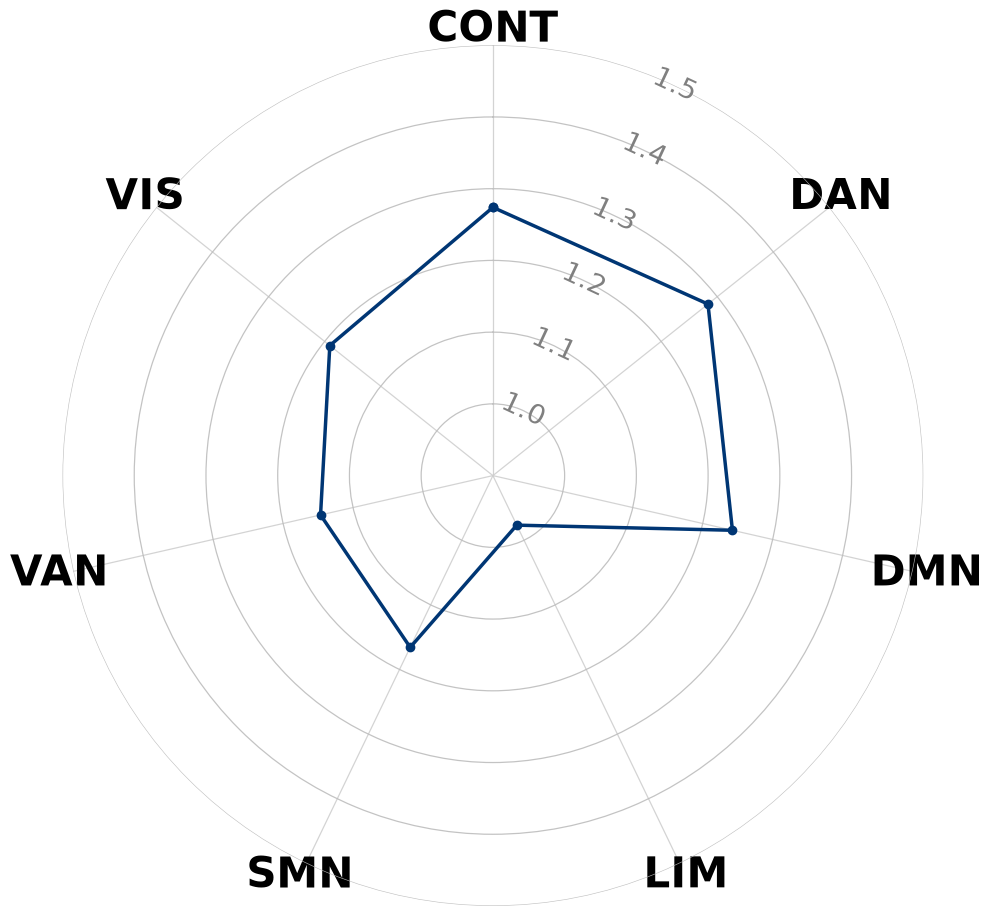

In [9]:
mean = df.groupby(NETWORK_COL)[VALUE_COL].mean().reset_index()


plot_network_task_radarplot_from_values(
    values=[mean[VALUE_COL].values],
    std_values= [[0] * len(mean[VALUE_COL].values)],
    networks=mean[NETWORK_COL].values,
    tasks = ['discovery'],
    task_colors = [max_color],
    figsize=(10, 10),
    save_path=f"{output_path}/mean_hurst_radarplot.png",
    TICKSIZE=TICKSIZE,
    LABELSIZE=LABELSIZE,
)